# Week 04 ? Task 02: Smoothing, windows and panel shape

All calculations use the cleaned daily session series from the supplied hourly data. The cleaning pipeline parses mixed timestamp formats, removes duplicate timestamps, removes `-1` sentinels, resamples to daily totals, reindexes the calendar, and excludes the partial final month (December 2025, observed only through 8 December).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path.cwd()
if not (DATA / "sessions_hourly.csv").exists():
    DATA = Path(r"D:\University\ML Lab\Week04")
plt.style.use("seaborn-v0_8-whitegrid")

## Part D cleaning used by Part B

In [2]:
raw = pd.read_csv(DATA / "sessions_hourly.csv")
raw["timestamp"] = pd.to_datetime(raw["ts"], format="mixed", dayfirst=True, errors="raise")
print("Raw rows:", len(raw))
print("Timestamp range:", raw["timestamp"].min(), "to", raw["timestamp"].max())
print("Duplicate timestamps:", int(raw["timestamp"].duplicated().sum()))
print("Sentinel sessions (-1):", int((raw["sessions"] < 0).sum()))

# Keep one record per timestamp, remove sentinels, then aggregate to calendar days.
clean_hourly = (
    raw.loc[raw["sessions"] >= 0]
    .drop_duplicates(subset="timestamp", keep="first")
    .set_index("timestamp")["sessions"]
    .sort_index()
)
daily_all = clean_hourly.resample("D").sum().asfreq("D")
calendar = pd.date_range(daily_all.index.min(), daily_all.index.max(), freq="D")
daily_all = daily_all.reindex(calendar)
partial_month = daily_all.index.max().to_period("M")
daily = daily_all.loc[daily_all.index.to_period("M") < partial_month].fillna(0)

print("Clean hourly rows:", len(clean_hourly))
print("Daily calendar rows before final-month exclusion:", len(daily_all))
print("Calendar gaps after reindex:", int(daily_all.isna().sum()))
print("Excluded partial final month:", partial_month, "(observed days:", int((daily_all.index.to_period("M") == partial_month).sum()), ")")
print("Working daily series:", daily.index.min().date(), "to", daily.index.max().date(), "(" + str(len(daily)) + " days)")
assert daily.loc["2024-11-29"] == 113710

Raw rows: 12670
Timestamp range: 2024-01-04 00:00:00 to 2025-12-08 23:00:00
Duplicate timestamps: 921
Sentinel sessions (-1): 290
Clean hourly rows: 11494
Daily calendar rows before final-month exclusion: 705
Calendar gaps after reindex: 0
Excluded partial final month: 2025-12 (observed days: 8 )
Working daily series: 2024-01-04 to 2025-11-30 (697 days)


## 1. Window report: 7, 28 and 91 days

A centered rolling mean loses `floor(window/2)` periods at each end. The variation share below is the fraction of raw variance removed by the smoother, computed as `1 - Var(raw - smooth) / Var(raw)` on the common non-null dates.

In [3]:
def window_report(series, windows=(7, 28, 91)):
    rows = []
    for window in windows:
        smooth = series.rolling(window, center=True).mean()
        common = smooth.dropna().index
        removed = 1 - (series.loc[common] - smooth.loc[common]).var() / series.loc[common].var()
        rows.append({
            "window_days": window,
            "cycle_removed": {7: "weekly", 28: "approximately four-week", 91: "approximately quarterly"}.get(window, f"{window}-day"),
            "raw_variation_removed_pct": removed * 100,
            "periods_lost_each_end": window // 2,
        })
    return pd.DataFrame(rows)

reports = window_report(daily)
print(reports.to_string(index=False, formatters={"raw_variation_removed_pct": "{:.2f}".format}))

 window_days           cycle_removed raw_variation_removed_pct  periods_lost_each_end
           7                  weekly                     67.08                      3
          28 approximately four-week                     45.66                     14
          91 approximately quarterly                     31.21                     45


**Choice for Part D.** I would use the 7-day window when the target is weekly seasonality: it cancels the day-of-week cycle while preserving monthly and quarterly movement. A 28- or 91-day window would remove longer business cycles that may be the signal of interest; choosing them only because they look smoother would be an unsupported visual claim.

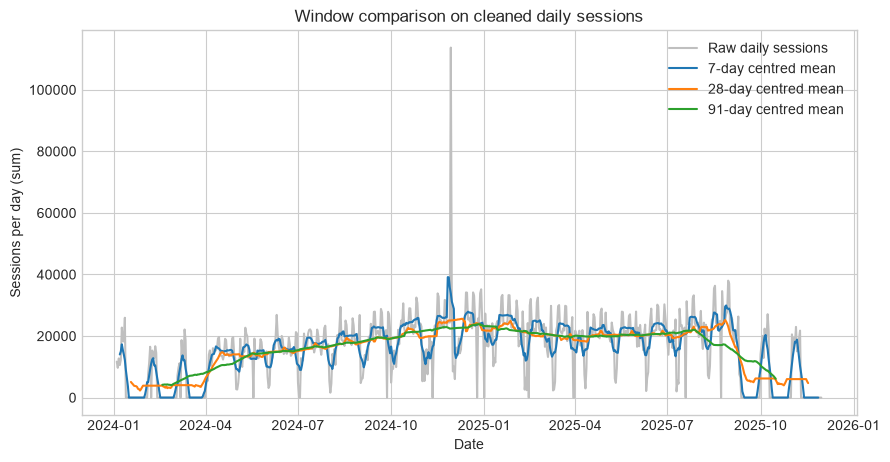

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(daily, color="0.75", label="Raw daily sessions")
for w, color in zip((7, 28, 91), ("tab:blue", "tab:orange", "tab:green")):
    ax.plot(daily.rolling(w, center=True).mean(), label=f"{w}-day centred mean")
ax.set(title="Window comparison on cleaned daily sessions", xlabel="Date", ylabel="Sessions per day (sum)")
ax.legend(); plt.show()

## 2. Three smoothers against Black Friday

The specified 14-day centered smoothers are evaluated at 29 November 2024. The EWMA is included as a causal, exponentially weighted comparison; unlike the centered mean and median, it does not use future observations.

In [5]:
black_friday = pd.Timestamp("2024-11-29")
mean_14 = daily.rolling(14, center=True).mean()
median_14 = daily.rolling(14, center=True).median()
ewma_14 = daily.ewm(span=14, adjust=False).mean()
print("Raw Black Friday:", int(daily.loc[black_friday]))
print("14-day centred mean:", mean_14.loc[black_friday])
print("14-day centred median:", median_14.loc[black_friday])
print("14-day EWMA:", ewma_14.loc[black_friday])

Raw Black Friday: 113710
14-day centred mean: 27473.5
14-day centred median: 23875.0
14-day EWMA: 36486.93803985416


**Dashboard versus quarterly report.** For a live morning dashboard I would use the EWMA, because it is causal and does not revise yesterday?s value using future data; the caption must say **?14-day EWMA, causal; raw daily sessions retained.?** For a quarterly report I would use the centered median when the goal is a robust description of the typical level around an isolated spike; the caption must say **?14-day centered rolling median; raw daily sessions retained.?**

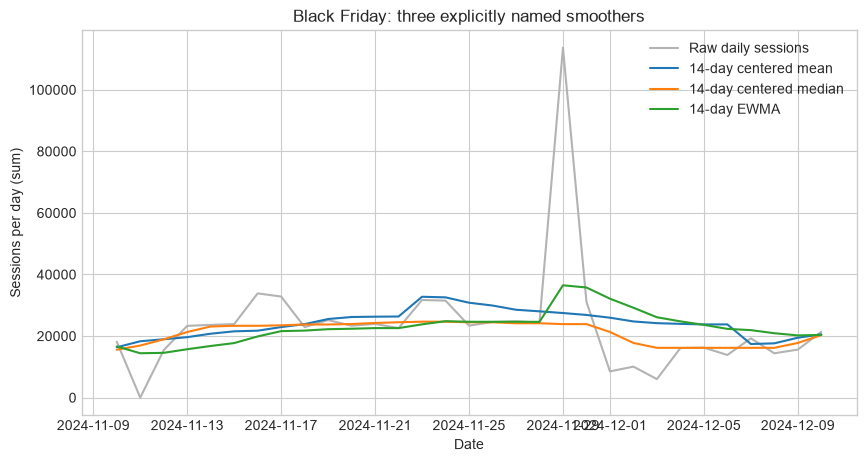

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
window = daily.loc["2024-11-10":"2024-12-10"]
ax.plot(window, color="0.7", label="Raw daily sessions")
ax.plot(mean_14.loc[window.index], label="14-day centered mean")
ax.plot(median_14.loc[window.index], label="14-day centered median")
ax.plot(ewma_14.loc[window.index], label="14-day EWMA")
ax.set(title="Black Friday: three explicitly named smoothers", xlabel="Date", ylabel="Sessions per day (sum)")
ax.legend(); plt.show()

## 3. Additive decomposition

The notebook uses `statsmodels.tsa.seasonal.seasonal_decompose` when available. A transparent additive fallback is included so the calculations remain executable if the optional package is unavailable.

In [7]:
try:
    from statsmodels.tsa.seasonal import seasonal_decompose
    decomposition_method = "statsmodels seasonal_decompose"
except ModuleNotFoundError:
    from types import SimpleNamespace
    def seasonal_decompose(series, model="additive", period=7, extrapolate_trend=False):
        if model != "additive":
            raise ValueError("Fallback supports additive decomposition only")
        trend = series.rolling(period, center=True).mean()
        detrended = series - trend
        phase = np.arange(len(series)) % period
        seasonal_values = pd.Series(detrended.groupby(phase).mean(), index=range(period))
        seasonal = pd.Series([seasonal_values[i] for i in phase], index=series.index)
        seasonal = seasonal - seasonal.mean()
        resid = series - trend - seasonal
        return SimpleNamespace(observed=series, trend=trend, seasonal=seasonal, resid=resid)
    decomposition_method = "documented additive fallback"

weekly = seasonal_decompose(daily, model="additive", period=7, extrapolate_trend=False)
weekly_amplitude = weekly.seasonal.max() - weekly.seasonal.min()
print("Method:", decomposition_method)
print("Weekly seasonal peak-to-trough amplitude:", weekly_amplitude)
print("Largest weekly residual:", weekly.resid.idxmax().date(), weekly.resid.max())

annual = seasonal_decompose(daily, model="additive", period=365, extrapolate_trend=False)
print("Annual seasonal peak-to-trough amplitude:", annual.seasonal.max() - annual.seasonal.min())
print("Largest annual residual:", annual.resid.idxmax().date(), annual.resid.max())

Method: documented additive fallback
Weekly seasonal peak-to-trough amplitude: 3812.437229437229
Largest weekly residual: 2024-11-29 80051.28804333475
Annual seasonal peak-to-trough amplitude: 114726.53150684932
Largest annual residual: 2024-07-07 1342.611586487481


With `period=365`, slow annual-scale movement that was left in the weekly decomposition?s residual is represented by the seasonal component instead; the residual therefore focuses on departures from both weekly and annual structure.

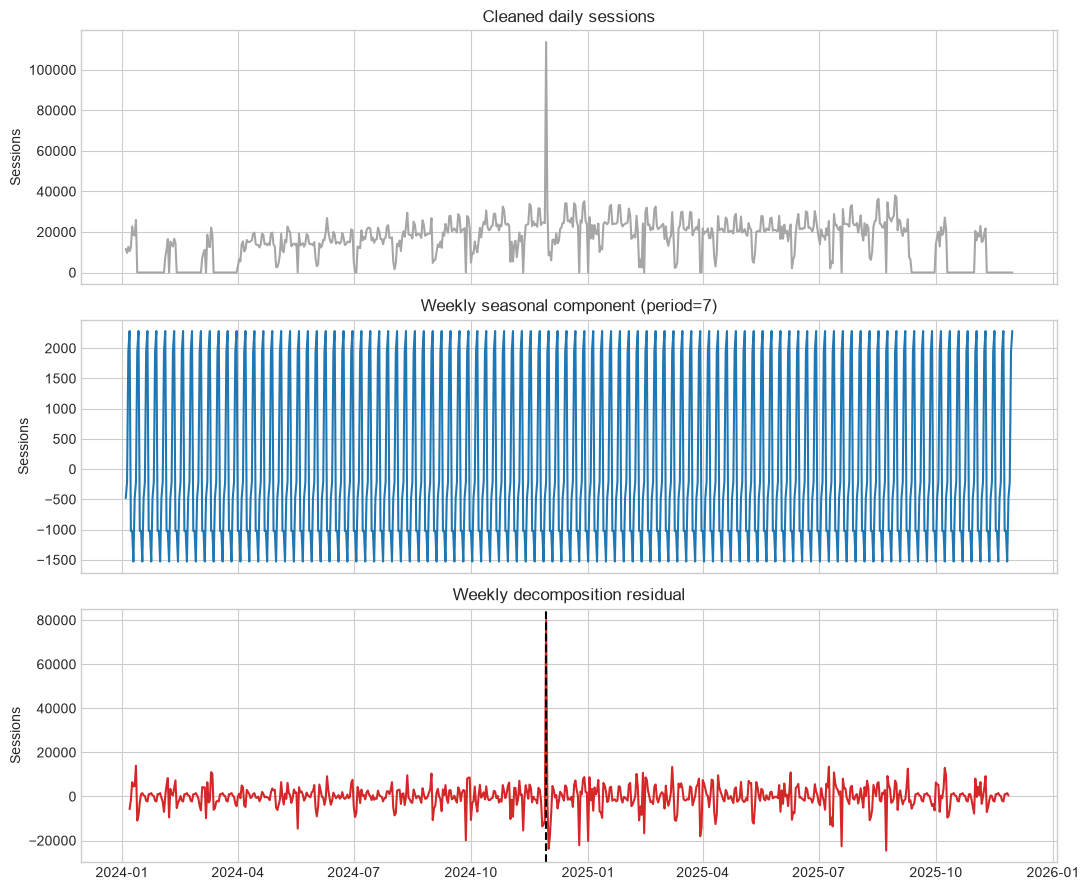

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
axes[0].plot(daily, color="0.65"); axes[0].set_title("Cleaned daily sessions")
axes[1].plot(weekly.seasonal, color="tab:blue"); axes[1].set_title("Weekly seasonal component (period=7)")
axes[2].plot(weekly.resid, color="tab:red"); axes[2].axvline(weekly.resid.idxmax(), color="black", linestyle="--")
axes[2].set_title("Weekly decomposition residual")
for ax in axes: ax.set_ylabel("Sessions")
plt.tight_layout(); plt.show()

## 4. Trailing or centered

`lag_at_turn()` is implemented as the displacement between the extrema of the 31-day trailing and centered means. The half-window is 15 days.

In [9]:
def lag_at_turn(series, window=31):
    trailing = series.rolling(window, min_periods=window).mean()
    centered = series.rolling(window, center=True, min_periods=window).mean()
    trailing_turn = trailing.idxmax()
    centered_turn = centered.idxmax()
    return {
        "trailing_turn": trailing_turn,
        "centered_turn": centered_turn,
        "lag_days": (trailing_turn - centered_turn).days,
        "half_window_days": window // 2,
    }

lag = lag_at_turn(daily, 31)
print(lag)

{'trailing_turn': Timestamp('2024-12-23 00:00:00'), 'centered_turn': Timestamp('2024-12-08 00:00:00'), 'lag_days': 15, 'half_window_days': 15}


A live dashboard that refreshes every morning must show the **31-day trailing** smoother, because a centered smoother uses future values and will revise history. Its caption must say **?31-day trailing rolling mean; causal; raw daily sessions retained.?** A centered smoother is appropriate only for retrospective analysis and must be labeled as centered.

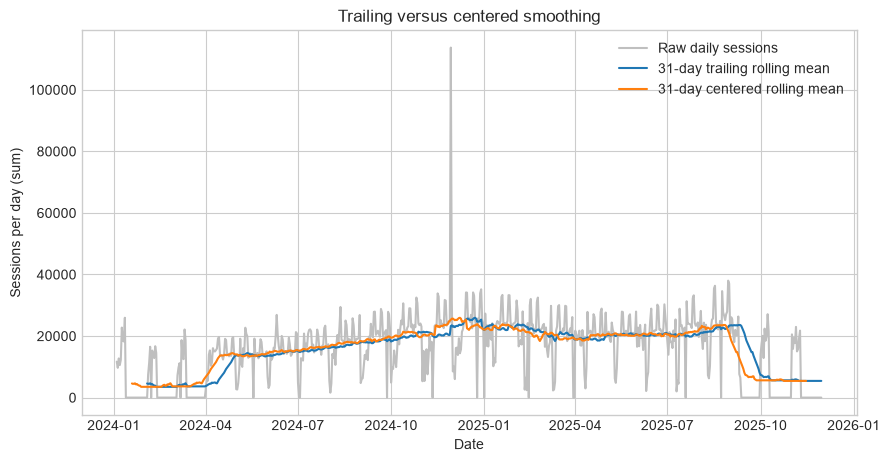

In [10]:
trailing_31 = daily.rolling(31, min_periods=31).mean()
centered_31 = daily.rolling(31, center=True, min_periods=31).mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(daily, color="0.75", label="Raw daily sessions")
ax.plot(trailing_31, label="31-day trailing rolling mean")
ax.plot(centered_31, label="31-day centered rolling mean")
ax.set(title="Trailing versus centered smoothing", xlabel="Date", ylabel="Sessions per day (sum)")
ax.legend(); plt.show()

## 5. Window framing and trend-direction counts

The 12 start months are January?December 2024. For each of five windows, an ordinary least-squares line is fitted to the daily values in that window.

In [11]:
start_months = pd.date_range("2024-01-01", periods=12, freq="MS")
window_lengths = [7, 14, 28, 56, 91]
trend_rows = []
for start in start_months:
    for length in window_lengths:
        values = daily.loc[start:start + pd.Timedelta(days=length - 1)]
        slope = np.polyfit(np.arange(len(values)), values.to_numpy(), 1)[0]
        trend_rows.append({"start_month": start, "window_days": length, "slope": slope,
                           "direction": "rising" if slope > 0 else "falling" if slope < 0 else "flat"})
trend_table = pd.DataFrame(trend_rows)
print(trend_table["direction"].value_counts().to_dict())
print("Rising:", int((trend_table.direction == "rising").sum()))
print("Falling:", int((trend_table.direction == "falling").sum()))
assert len(trend_table) == 60

{'rising': 52, 'falling': 8}
Rising: 52
Falling: 8


**Why a Lie Factor cannot be computed for a cherry-picked window.** Tufte?s formula assumes an effect in the data?a defined comparison or baseline?exists independently of the framing. A cherry-picked window changes the estimand and can make a selected segment rise or fall, so there is no unique ?effect in the data? against which to compare the visual effect. The honest substitute is to disclose the selection rule, report all 60 direction results (52 rising and 8 falling), show the complete cleaned series, and state the window, endpoint loss, and fitted slope rather than inventing a single Lie Factor.

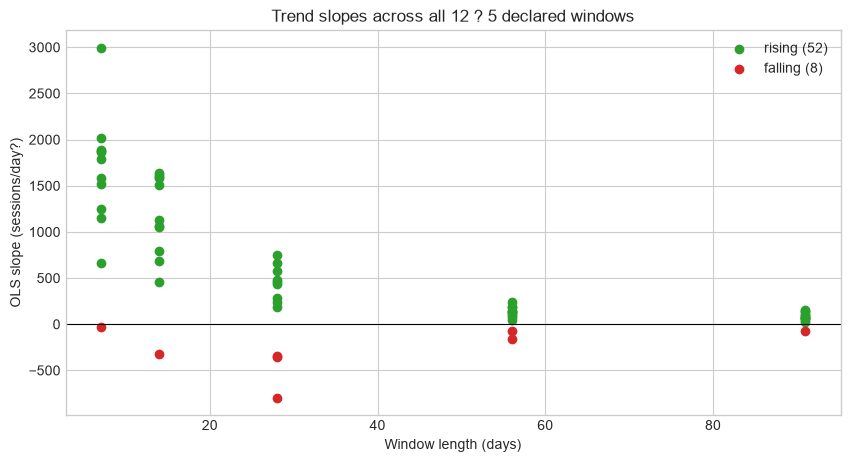

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
for direction, color in [("rising", "tab:green"), ("falling", "tab:red")]:
    subset = trend_table[trend_table.direction == direction]
    ax.scatter(subset.window_days, subset.slope, label=f"{direction} ({len(subset)})", color=color)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Trend slopes across all 12 ? 5 declared windows", xlabel="Window length (days)", ylabel="OLS slope (sessions/day?)")
ax.legend(); plt.show()